# Why does Mellin appear?

The first animation phase tracks only corresponding points under $x=e^t$. The second phase transforms the example $f(x)=e^{-x}$ by $E_{p,w_\delta}$.

In [1]:
# ============================================================
# USER PARAMETERS
# ============================================================
# MATHEMATICAL PARAMETERS
p = 2.0
delta = 0.0
# ANIMATION PARAMETERS
FPS = 24
SPEED_FACTOR = 1.0
BASE_DURATION = 7.0

## Step 1: points before functions

The map $t=\log x$ sends $0^+$ toward $-\infty$, $1$ to $0$, and $+\infty$ toward $+\infty$. The two dots move together while the lower function panels remain absent.

In [2]:
from pathlib import Path
import sys
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
elif not (project_dir / "src" / "geometry.py").exists():
    project_dir = project_dir / "karlovich_2025_cusps"
if not (project_dir / "src" / "geometry.py").exists():
    raise FileNotFoundError("Run this notebook from its project folder or the repository root.")
sys.path.insert(0, str(project_dir / "src"))
output_dir = project_dir / "outputs"

import numpy as np
from render_log_transport import render_log_transport
assert p > 1 and -1/p < delta < 1-1/p
assert FPS > 0 and SPEED_FACTOR > 0 and BASE_DURATION > 0
nu = 1/p + delta
for t in (-3.0, 0.0, 3.0):
    x = np.exp(t)
    assert np.isclose(np.log(x), t)
    print(f"t={t:+.1f} <-> x={x:.4f}")
print(f"nu = 1/p + delta = {nu:.3f}")

t=-3.0 <-> x=0.0498
t=+0.0 <-> x=1.0000
t=+3.0 <-> x=20.0855
nu = 1/p + delta = 0.500


## Step 2: functions after points

For $w_\delta(x)=x^\delta$, the logarithmic coordinate isometry used here is
$$ (E_{p,w_\delta}f)(t)=e^{\nu t}f(e^t),\qquad \nu=1/p+\delta. $$
With $f(x)=e^{-x}$, the right-hand curve is $e^{\nu t-e^t}$. This is the coordinate change that turns dilation structure on $\mathbb R_+$ into translation structure on $\mathbb R$.

gif: outputs/log_transport_v1.gif
mp4: outputs/log_transport_v1.mp4
png: outputs/log_transport_v1.png
pdf: outputs/log_transport_v1_static.pdf
168 frames; 7.00 seconds


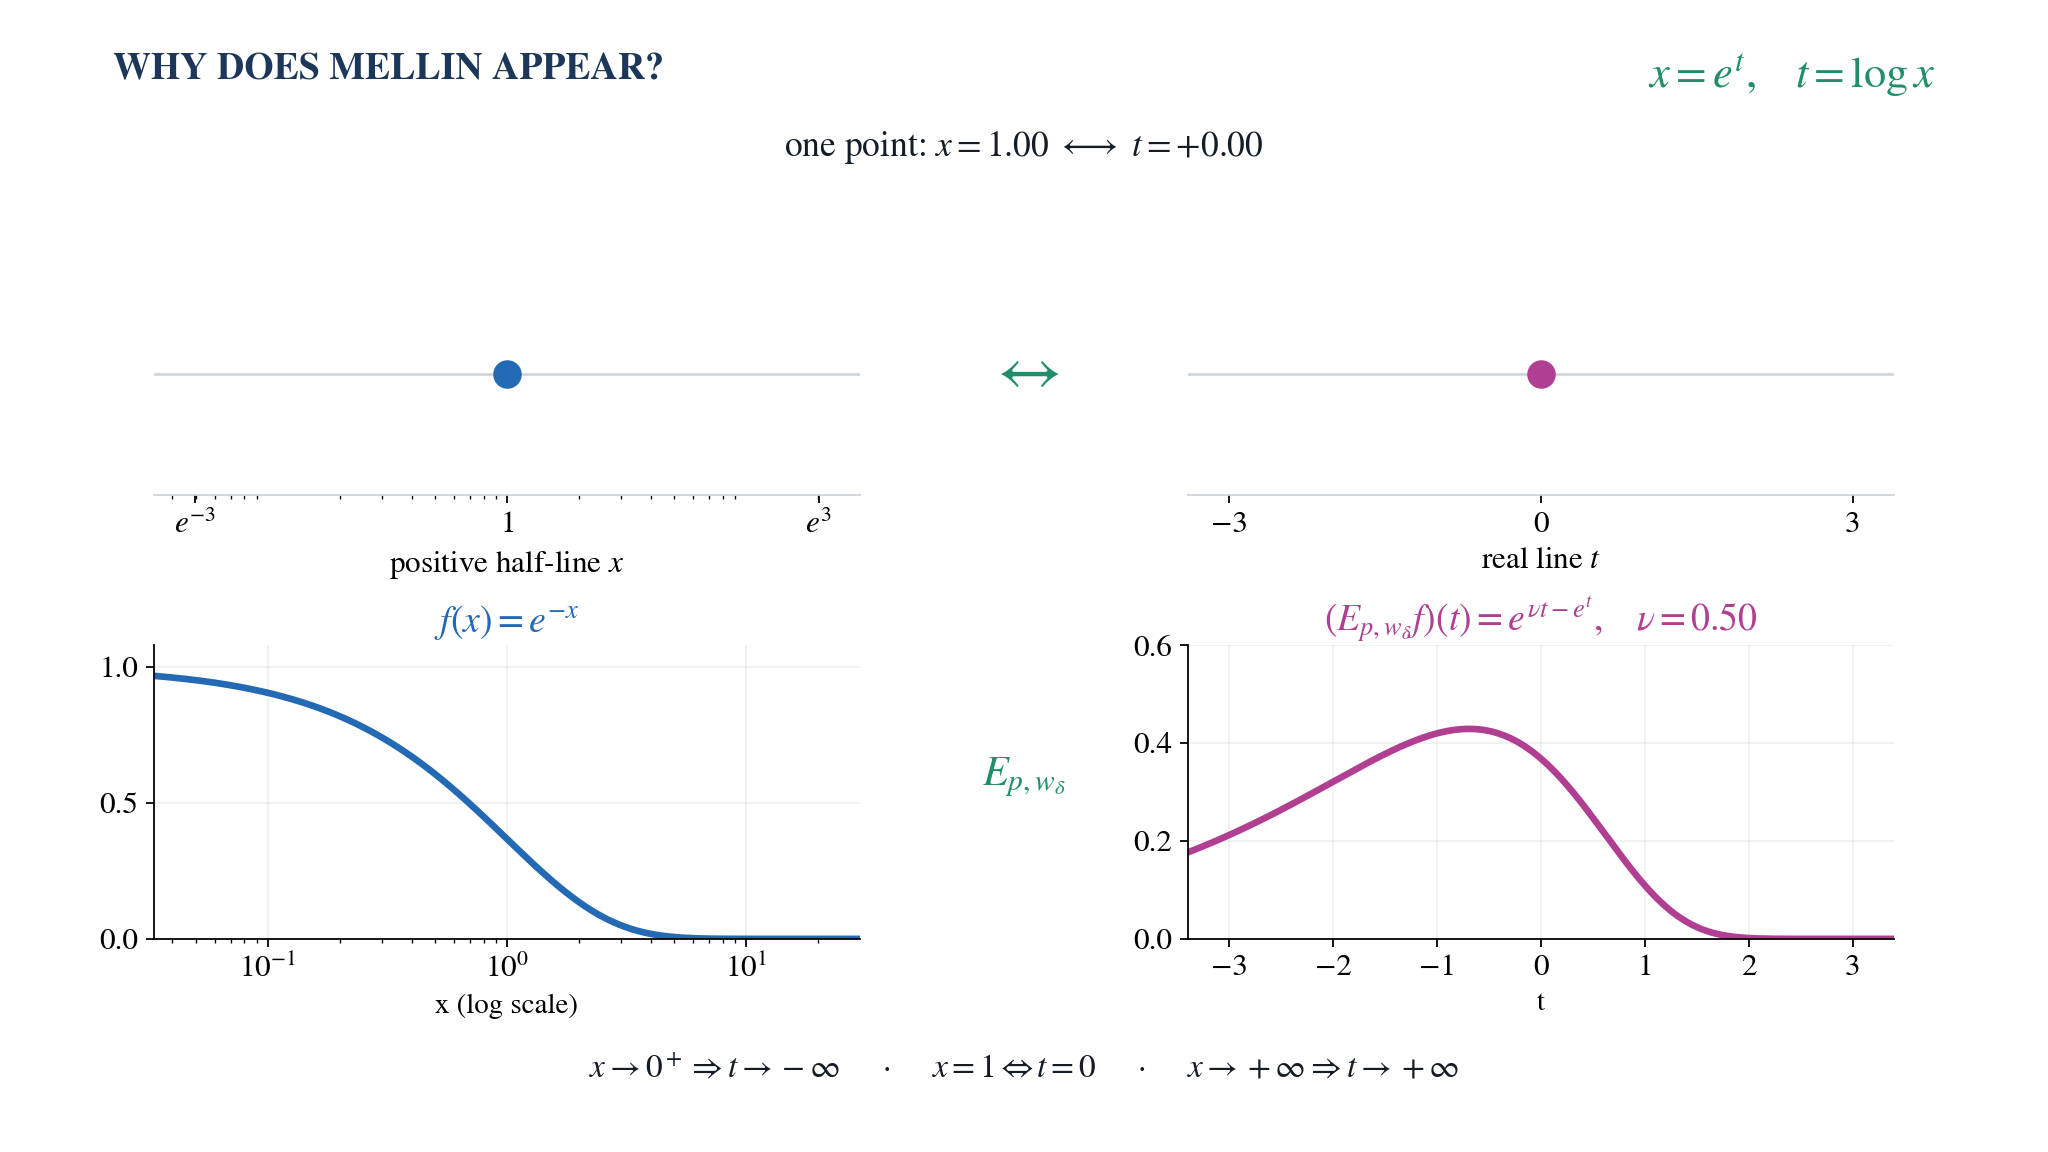

In [3]:
from IPython.display import Image, display
assets = render_log_transport(output_dir, p=p, delta=delta, fps=FPS,
                              duration=BASE_DURATION, speed_factor=SPEED_FACTOR)
for key in ("gif", "mp4", "png", "pdf"):
    print(f"{key}: {assets[key].relative_to(project_dir)}")
print(f"{assets['frames']} frames; {assets['duration_seconds']:.2f} seconds")
display(Image(filename=str(assets["png"])))

## Read the picture

The dots establish $x\leftrightarrow t$ before any function appears. The lower panels then show the original $f$ and its weighted logarithmic transform. The formula depends on $\nu$, so changing $p$ or $\delta$ changes the transformed curve.

Executable source: [render_log_transport.py](../src/render_log_transport.py).

<!-- resultado-verificado: log_math -->